# Predicting departure delays before departure

**Question:** can scheduled and calendar information identify flights departing at least 15 minutes late?

Run `python -m src.predict` once in the verified environment before opening this notebook. This notebook reads the saved evaluation and pipeline: rerunning it never retrains models or repeats test evaluation. Figures are refreshed under `outputs/figures/`.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src/predict.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.prepare import FEATURES
TABLES = ROOT / 'outputs/tables'
MODELS = ROOT / 'outputs/models'
FIGURES = ROOT / 'outputs/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
assert (TABLES / 'prediction_comparison.csv').exists(), 'Run python -m src.predict once first.'
metrics = pd.read_csv(TABLES / 'prediction_comparison.csv')
monthly = pd.read_csv(TABLES / 'prediction_monthly.csv')
coverage = pd.read_csv(TABLES / 'prediction_split_coverage.csv')
selection = json.loads((MODELS / 'prediction_selection.json').read_text())
assert selection['features'] == FEATURES
assert hashlib.sha256((ROOT / 'data/processed/classifier.csv').read_bytes()).hexdigest() == selection['source_sha256']
print('Notebook Python:', sys.version.split()[0])
print('Training environment:', selection['python_version'], '| sklearn:', selection['sklearn_version'])
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False})
def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close()

Matplotlib is building the font cache; this may take a moment.


Notebook Python: 3.13.13
Training environment: 3.13.13 | sklearn: 1.7.2


## Chronology and leakage controls

January–August trains every estimator and preprocessing step. September–October selects thresholds and the winner using **F1**. All four thresholds and the selected model are frozen in `prediction_selection.json` before the single November–December comparison. The test comparison is descriptive and cannot change that decision. There is no refit on validation.

Only `src.prepare.FEATURES` enters the pipelines. Flight number, carrier, origin and destination are categorical. One-hot encoding ignores unseen categories; numerical inputs are median-imputed and standardized. Imputers, scales and category vocabularies see training only. Metadata, observed times and delays, missing-label indicators, clusters and anomalies never enter the predictors. Full-year EDA remains historical description.

The coverage below documents the observed-label population. Missing departure delays are unknown, not on-time or confirmed cancellations.

In [2]:
display(coverage)
print('Approved predictors:', FEATURES)
print('Categorical predictors:', selection['categorical_features'])

,split,n,positive_count,prevalence,negative_count
0,test,54145,11815,0.218210,42330
1,train,218601,52765,0.241376,165836
2,validation,55775,8334,0.149422,47441


Approved predictors: ['month', 'day_of_week', 'day_of_year', 'is_weekend', 'sched_dep_minutes', 'sched_arr_minutes', 'carrier', 'flight', 'origin', 'dest', 'distance']
Categorical predictors: ['carrier', 'flight', 'origin', 'dest']


## Four required comparisons

- **Majority baseline:** always predicts the training majority class; it tests whether accuracy from predicting on-time flights would conceal failure to detect delays.
- **Logistic regression:** an additive model using scaled numerical variables and encoded categories.
- **Decision tree:** a bounded tree that can capture interactions with depth and leaf-size limits.
- **Random forest:** averages 100 bounded trees to reduce dependence on a single tree.

Hyperparameters are fixed and recorded in the selection metadata. There is no broad parameter search. For each learned model, a small threshold grid (0.10–0.50, step 0.025) is searched on validation F1. The baseline retains threshold 0.5. Threshold ties favor proximity to 0.5; model ties are alphabetical.

,constant,random_state,strategy,C,class_weight,dual,fit_intercept,intercept_scaling,l1_ratio,max_iter,...,min_impurity_decrease,min_samples_leaf,min_samples_split,min_weight_fraction_leaf,monotonic_cst,splitter,bootstrap,max_samples,n_estimators,oob_score
majority_baseline,None,None,most_frequent,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
logistic_regression,NaN,42,NaN,1.0,None,False,True,1,None,500,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_tree,NaN,42,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,...,0.0,100,2,0.0,None,best,NaN,NaN,NaN,NaN
random_forest,NaN,42,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,...,0.0,30,2,0.0,None,NaN,True,None,100,False


,model,threshold,precision,recall,f1,roc_auc,n,prevalence
1,logistic_regression,0.325,0.233022,0.615911,0.338120,0.675439,55775,0.149422
3,random_forest,0.250,0.219188,0.713583,0.335363,0.675547,55775,0.149422
2,decision_tree,0.175,0.221858,0.600912,0.324069,0.630173,55775,0.149422
0,majority_baseline,0.500,NaN,0.000000,0.000000,0.500000,55775,0.149422


Selected **logistic_regression**, threshold **0.325**, using validation F1 only.

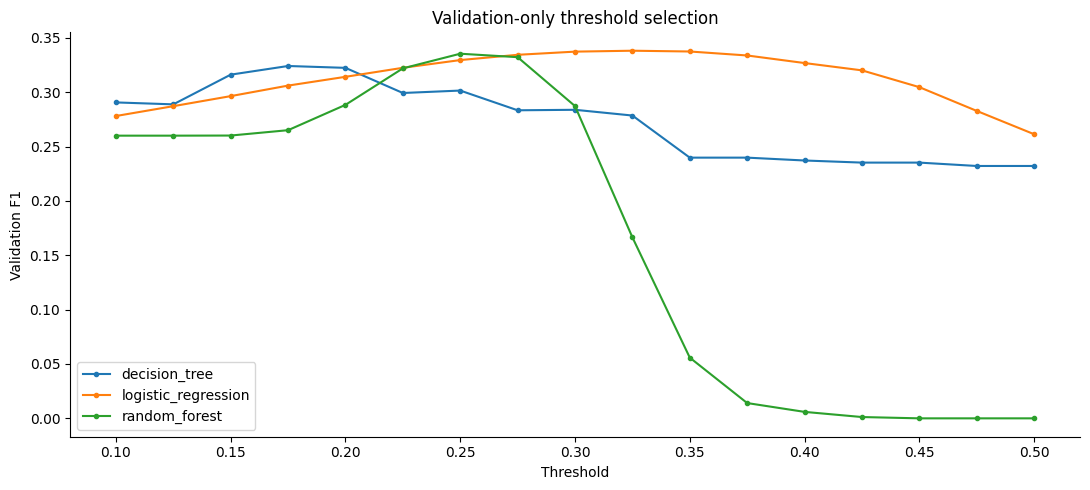

In [3]:
display(pd.DataFrame(selection['parameters']).T)
validation = metrics.loc[metrics.split.eq('validation')].sort_values('f1', ascending=False)
columns = ['model', 'threshold', 'precision', 'recall', 'f1', 'roc_auc', 'n', 'prevalence']
display(validation[columns])
display(Markdown(f"Selected **{selection['selected_model']}**, threshold **{selection['threshold']:.3f}**, using validation F1 only."))
search = pd.read_csv(TABLES / 'prediction_threshold_search.csv')
for name, group in search.groupby('model'):
    plt.plot(group.threshold, group.f1, marker='.', label=name)
plt.xlabel('Threshold'); plt.ylabel('Validation F1'); plt.title('Validation-only threshold selection')
plt.legend(); save('prediction_threshold_selection')

## Frozen holdout results

Precision is the fraction of predicted delays that are actual delays; recall is the fraction of actual delays detected. F1 balances precision and recall. ROC-AUC measures ranking using probabilities, not hard predictions, and does not establish calibration.

Undefined metrics remain NaN (blank in CSV): precision when no positives are predicted, recall when no actual positives exist, F1 when its denominator is zero, and ROC-AUC for a single observed class. The baseline's precision is undefined; its zero recall and F1 are real failures to find delays.

,model,threshold,precision,recall,f1,roc_auc,n,prevalence,split
6,decision_tree,0.175,0.303205,0.564452,0.394499,0.615798,54145,0.218210,test
5,logistic_regression,0.325,0.305268,0.618028,0.408675,0.653322,54145,0.218210,test
4,majority_baseline,0.500,NaN,0.000000,0.000000,0.500000,54145,0.218210,test
7,random_forest,0.250,0.295889,0.662124,0.409003,0.645101,54145,0.218210,test
2,decision_tree,0.175,0.221858,0.600912,0.324069,0.630173,55775,0.149422,validation
1,logistic_regression,0.325,0.233022,0.615911,0.338120,0.675439,55775,0.149422,validation
0,majority_baseline,0.500,NaN,0.000000,0.000000,0.500000,55775,0.149422,validation
3,random_forest,0.250,0.219188,0.713583,0.335363,0.675547,55775,0.149422,validation


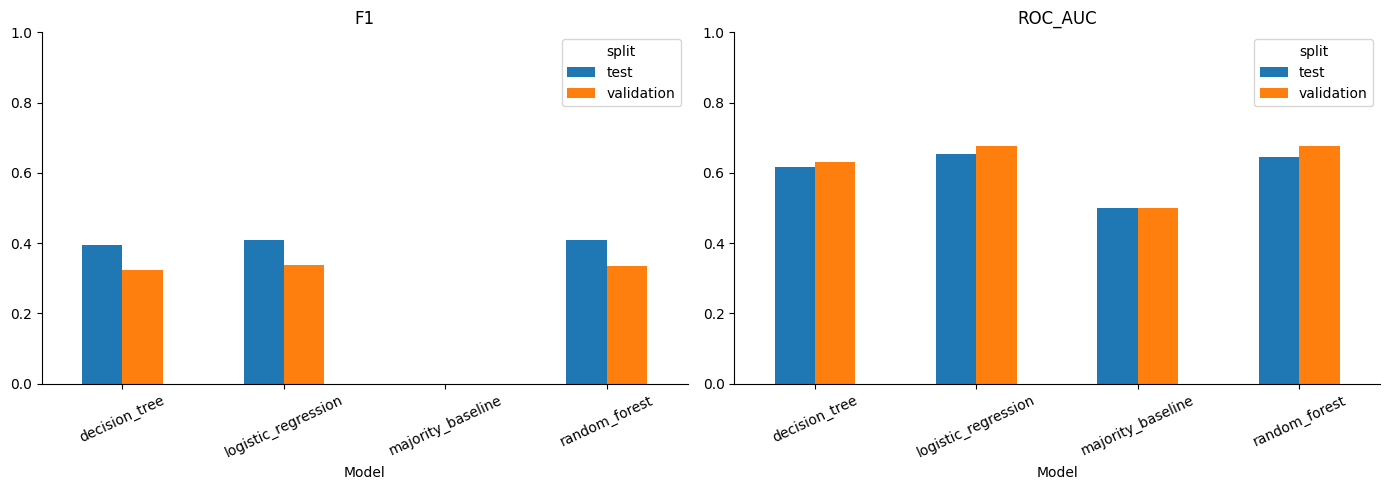

The validation-selected model has validation F1 **0.338** and test F1 **0.409**. Test precision is **0.305**, recall **0.618**, and ROC-AUC **0.653**. These are the frozen model's holdout results; they are not used to revise its threshold.

In [4]:
display(metrics[columns + ['split']].sort_values(['split', 'model']))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['f1', 'roc_auc']):
    metrics.pivot(index='model', columns='split', values=metric).plot.bar(ax=ax)
    ax.set(title=metric.upper(), ylim=(0, 1), xlabel='Model')
    ax.tick_params(axis='x', rotation=25)
save('prediction_model_comparison')
selected_rows = metrics.loc[metrics.model.eq(selection['selected_model'])].set_index('split')
v, t = selected_rows.loc['validation'], selected_rows.loc['test']
display(Markdown(f"The validation-selected model has validation F1 **{v.f1:.3f}** and test F1 **{t.f1:.3f}**. Test precision is **{t.precision:.3f}**, recall **{t.recall:.3f}**, and ROC-AUC **{t.roc_auc:.3f}**. These are the frozen model's holdout results; they are not used to revise its threshold."))

## Confusion matrices

Rows are actual classes, columns are predicted classes, ordered on-time (0), delayed (1). Each panel shows actual counts, making the false-alarm and missed-delay trade-off explicit.

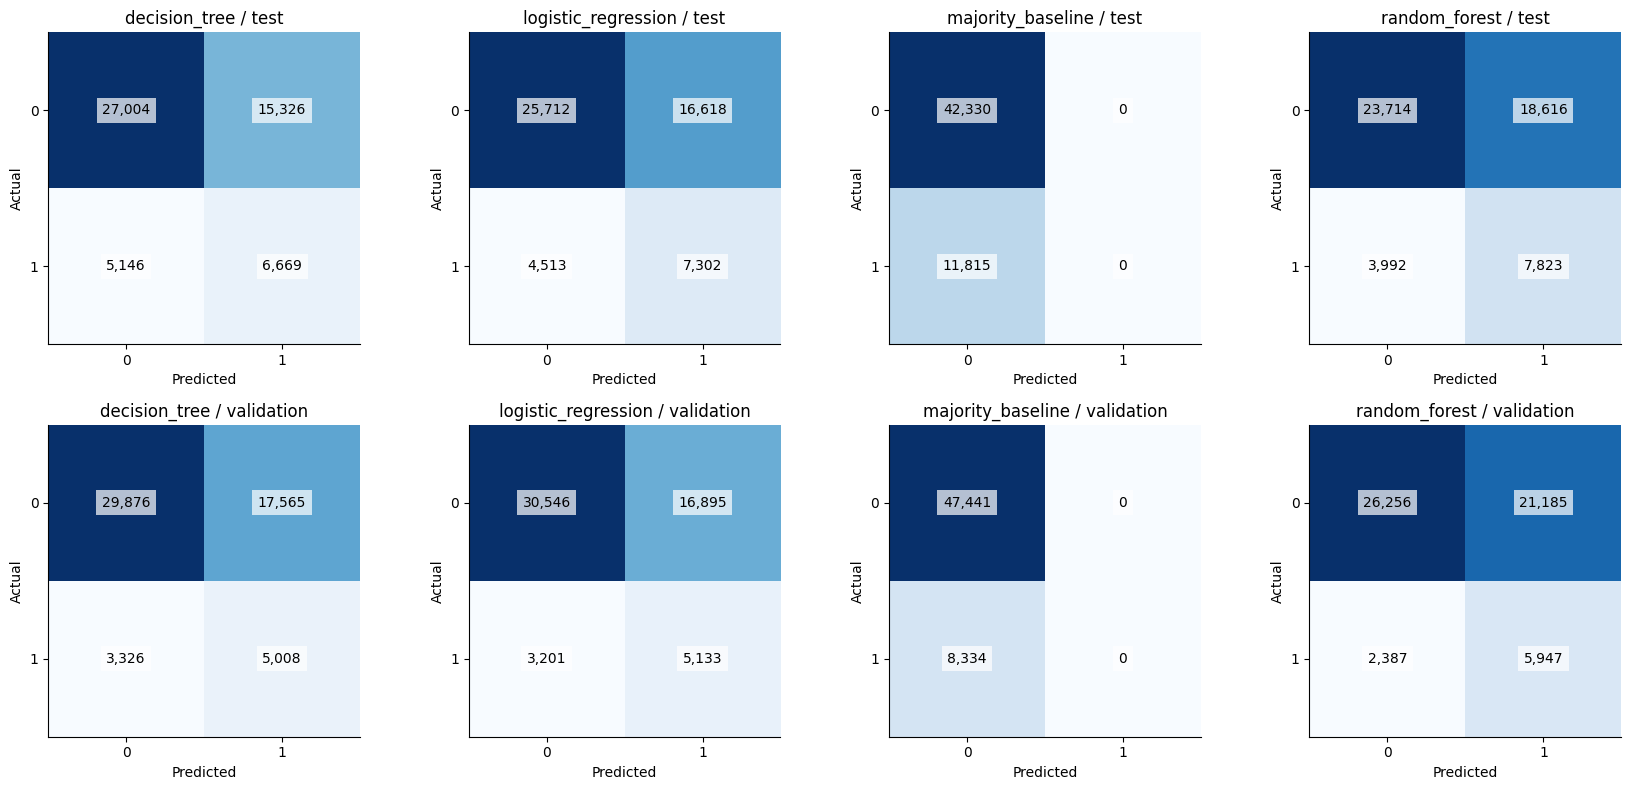

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, row in zip(axes.flat, metrics.sort_values(['split', 'model']).itertuples()):
    matrix = np.array([[row.tn, row.fp], [row.fn, row.tp]])
    ax.imshow(matrix, cmap='Blues')
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, f'{value:,}', ha='center', va='center', color='black', bbox=dict(facecolor='white', alpha=.7, edgecolor='none'))
    ax.set(title=f'{row.model} / {row.split}', xlabel='Predicted', ylabel='Actual', xticks=[0,1], yticks=[0,1])
save('prediction_confusion_matrices')

## Month-by-month performance

Each row reports sample size, actual class counts and prevalence alongside the metrics. September and October were used for selection; November and December are the final holdout. Monthly changes can reflect both a different delay prevalence and changes in schedules. One year's monthly differences do not establish recurring seasonal effects.

,model,split,month,n,negative_count,positive_count,prevalence,precision,recall,f1,roc_auc
0,majority_baseline,validation,9,27122,23214,3908,0.144090,NaN,0.000000,0.000000,0.500000
1,majority_baseline,validation,10,28653,24227,4426,0.154469,NaN,0.000000,0.000000,0.500000
2,logistic_regression,validation,9,27122,23214,3908,0.144090,0.220379,0.574463,0.318553,0.663322
3,logistic_regression,validation,10,28653,24227,4426,0.154469,0.243898,0.652508,0.355075,0.685994
4,decision_tree,validation,9,27122,23214,3908,0.144090,0.211105,0.584698,0.310209,0.635657
5,decision_tree,validation,10,28653,24227,4426,0.154469,0.231764,0.615228,0.336692,0.624664
6,random_forest,validation,9,27122,23214,3908,0.144090,0.207445,0.697288,0.319761,0.661570
7,random_forest,validation,10,28653,24227,4426,0.154469,0.230209,0.727971,0.349799,0.688012
8,majority_baseline,test,11,27035,22967,4068,0.150472,NaN,0.000000,0.000000,0.500000
9,majority_baseline,test,12,27110,19363,7747,0.285762,NaN,0.000000,0.000000,0.500000


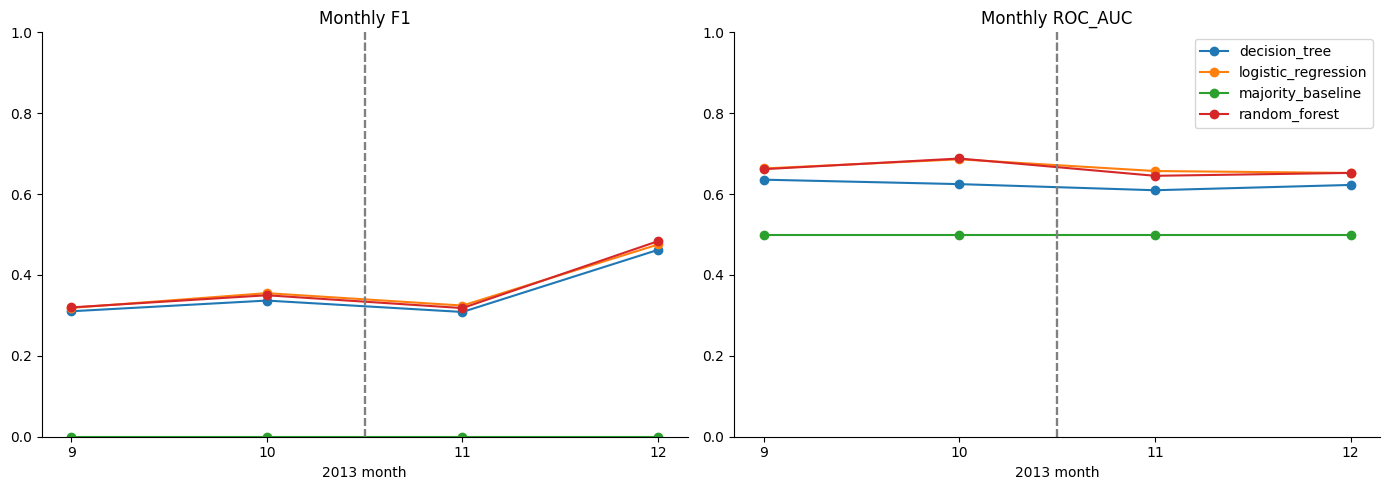

Month 9: n=27,122, prevalence=14.4%, F1=0.319, recall=0.574
Month 10: n=28,653, prevalence=15.4%, F1=0.355, recall=0.653
Month 11: n=27,035, prevalence=15.0%, F1=0.324, recall=0.629
Month 12: n=27,110, prevalence=28.6%, F1=0.475, recall=0.612


In [6]:
display(monthly[['model','split','month','n','negative_count','positive_count','prevalence','precision','recall','f1','roc_auc']])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, group in monthly.groupby('model'):
    for ax, metric in zip(axes, ['f1', 'roc_auc']):
        ax.plot(group.month, group[metric], marker='o', label=name)
        ax.set(title=f'Monthly {metric.upper()}', xlabel='2013 month', ylim=(0,1), xticks=[9,10,11,12])
        ax.axvline(10.5, color='gray', linestyle='--')
axes[1].legend(); save('prediction_monthly_performance')
selected_months = monthly.loc[monthly.model.eq(selection['selected_model'])]
for row in selected_months.itertuples():
    print(f'Month {row.month}: n={row.n:,}, prevalence={row.prevalence:.1%}, F1={row.f1:.3f}, recall={row.recall:.3f}')

## Dashboard artifact and limits

`outputs/models/flight_delay_pipeline.joblib` contains the full selected pipeline. Load it with the same scikit-learn environment, pass the approved feature columns, and apply the threshold in `prediction_selection.json` to the class-1 probabilities. No training is required. Metadata includes source checksum, feature roles, hyperparameters, versions and fit scope.

Schedule-only models omit weather and operational history. A low classification threshold may improve recall while generating many false alarms; the confusion matrices show this cost. F1 selection on two months can overfit validation. Trees cannot extrapolate calendar trends beyond their training range, and unseen categories provide no learned category effect. Results apply to observed labels in 2013 NYC departures, not cancellation prediction or causal airline reliability. Probabilities have not been calibrated. No test-driven retuning or advanced models are added.

In [7]:
pipeline = joblib.load(MODELS / 'flight_delay_pipeline.joblib')
print('Saved estimator:', type(pipeline.named_steps['model']).__name__)
print('Saved decision threshold:', selection['threshold'])
print('Detailed report:', ROOT / 'reports/prediction_findings.md')

Saved estimator: LogisticRegression
Saved decision threshold: 0.325
Detailed report: /Users/animusoyan/PycharmProjects/Data_Mining_Project/reports/prediction_findings.md
